# House Price Prediction: Six Regression Algorithms Compared
Alternative implementation with **manual preprocessing** (pandas) and a reusable training/evaluation function.
Same dataset, features, target and 80:20 split for every model.

## 1. Imports and configuration

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42
TARGET = "median_house_value"
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
sns.set_theme(style="whitegrid")

## 2. Load data and quick exploration

In [2]:
df = pd.read_csv(URL)
print("Rows, columns:", df.shape)
print("\nMissing values:")
print(df.isna().sum()[lambda s: s > 0])
print("\nTarget summary:")
print(df[TARGET].describe().round(0))

Rows, columns: (20640, 10)

Missing values:
total_bedrooms    207
dtype: int64

Target summary:
count     20640.0
mean     206856.0
std      115396.0
min       14999.0
25%      119600.0
50%      179700.0
75%      264725.0
max      500001.0
Name: median_house_value, dtype: float64


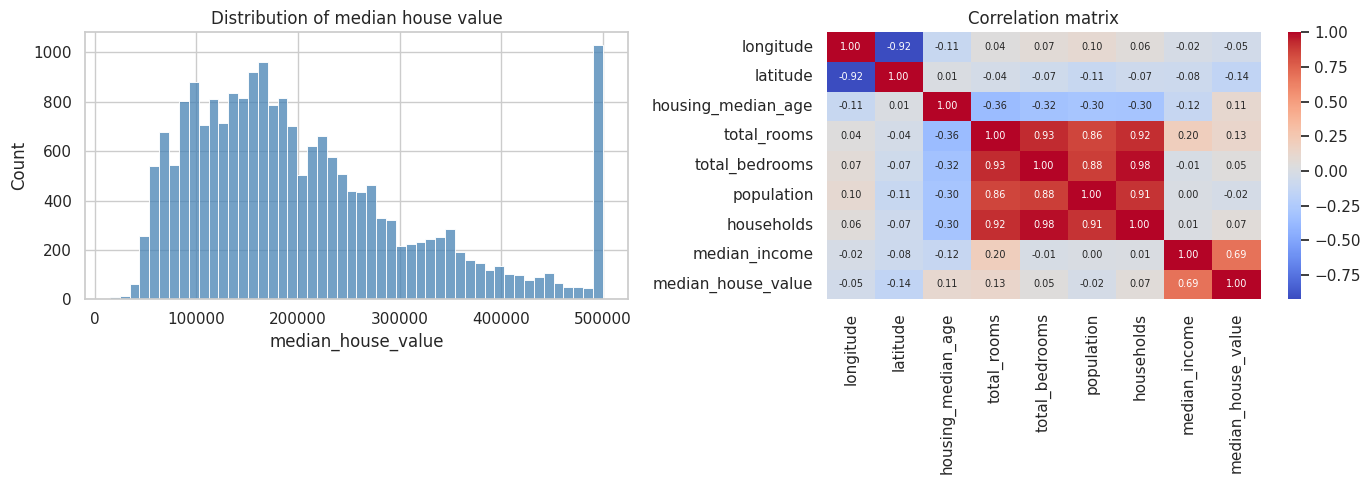

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df[TARGET], bins=50, ax=ax[0], color="steelblue")
ax[0].set_title("Distribution of median house value")
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm",
            annot_kws={"size": 7}, ax=ax[1])
ax[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

## 3. Preprocessing (manual)
1. One-hot encode `ocean_proximity` (special characters removed from column names because XGBoost rejects `<`).
2. Split 80:20.
3. Fill missing `total_bedrooms` with the **training** median.
4. Create standardised copies of the numeric columns (statistics from training data only) for the models that need scaling.

In [4]:
data = pd.get_dummies(df, columns=["ocean_proximity"], dtype=float)
data.columns = data.columns.str.replace(r"[<>\[\]]", "", regex=True)
y = data.pop(TARGET)

X_train, X_test, y_train, y_test = train_test_split(data, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)

# median imputation learned from the training set
median_bedrooms = X_train["total_bedrooms"].median()
X_train = X_train.fillna({"total_bedrooms": median_bedrooms})
X_test = X_test.fillna({"total_bedrooms": median_bedrooms})

# standardised copies (original numeric columns only; one-hot columns stay 0/1)
num_cols = df.drop(columns=[TARGET]).select_dtypes("number").columns.tolist()
scaler = StandardScaler().fit(X_train[num_cols])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

# target statistics (used only by the neural network)
y_mu, y_sd = y_train.mean(), y_train.std(ddof=0)
print("Missing after imputation:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))

Train: (16512, 13)  Test: (4128, 13)
Missing after imputation: 0


## 4. Model definitions
`scaled=True` means the model is trained on the standardised features. The neural network also learns a
standardised target, and its predictions are converted back to dollars.

In [5]:
MODELS = {
    "Linear Regression": dict(model=LinearRegression(), scaled=True),
    "Decision Tree":     dict(model=DecisionTreeRegressor(max_depth=8, random_state=SEED), scaled=False),
    "Random Forest":     dict(model=RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1), scaled=False),
    "Neural Network":    dict(model=MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                                                 max_iter=500, random_state=SEED), scaled=True, scale_target=True),
    "XGBoost":           dict(model=XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6,
                                                 random_state=SEED, n_jobs=-1), scaled=False),
    "KNN":               dict(model=KNeighborsRegressor(n_neighbors=5), scaled=True),
}

## 5. Train and evaluate

In [6]:
def train_and_evaluate(name, spec):
    Xtr, Xte = (X_train_s, X_test_s) if spec["scaled"] else (X_train, X_test)
    ytr = (y_train - y_mu) / y_sd if spec.get("scale_target") else y_train
    start = time.perf_counter()
    spec["model"].fit(Xtr, ytr)
    seconds = time.perf_counter() - start
    pred = spec["model"].predict(Xte)
    if spec.get("scale_target"):
        pred = pred * y_sd + y_mu
    mse = mean_squared_error(y_test, pred)
    metrics = {"Model": name, "MAE": mean_absolute_error(y_test, pred), "MSE": mse,
               "RMSE": np.sqrt(mse), "R2": r2_score(y_test, pred)}
    return metrics, pred, seconds

records, predictions, fit_times = [], {}, {}
for name, spec in MODELS.items():
    m, p, t = train_and_evaluate(name, spec)
    records.append(m); predictions[name] = p; fit_times[name] = t

results = (pd.DataFrame(records).sort_values("RMSE").reset_index(drop=True))
results.index = results.index + 1
results.to_csv("results_alt.csv", index_label="Rank")
results.style.format({"MAE": "{:,.0f}", "MSE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}"})

,Model,MAE,MSE,RMSE,R2
1,XGBoost,"30,508","2,127,857,554","46,129",0.8376
2,Random Forest,"31,487","2,383,729,508","48,823",0.8181
3,Neural Network,"35,958","2,856,244,086","53,444",0.7820
4,KNN,"40,763","3,758,885,714","61,310",0.7132
5,Decision Tree,"42,777","3,904,405,787","62,485",0.7020
6,Linear Regression,"50,670","4,908,290,571","70,059",0.6254


In [7]:
print("Training time (seconds):")
print(pd.Series(fit_times).round(2).sort_values().to_string())

Training time (seconds):
KNN                   0.04
Linear Regression     0.05
Decision Tree         0.42
XGBoost               1.51
Neural Network        6.93
Random Forest        35.23


## 6. Visual comparison

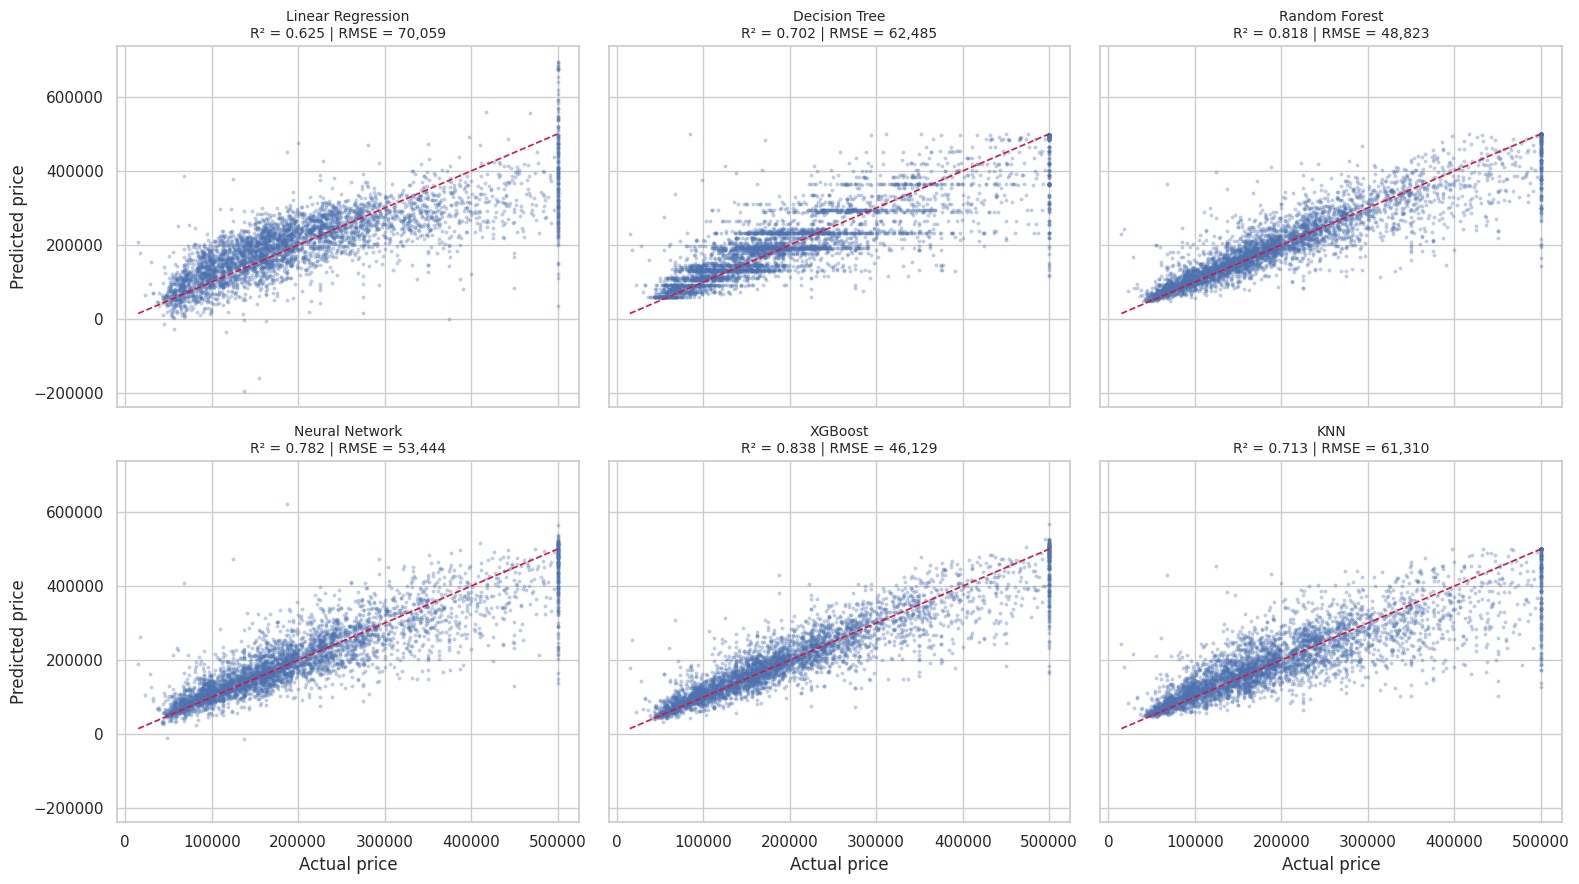

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
lo, hi = float(y_test.min()), float(y_test.max())
for ax, name in zip(axes.ravel(), MODELS):
    sns.scatterplot(x=y_test, y=predictions[name], s=6, alpha=0.35, ax=ax, edgecolor=None)
    ax.plot([lo, hi], [lo, hi], color="crimson", ls="--", lw=1.2)
    row = results.set_index("Model").loc[name]
    ax.set_title(f"{name}\nR² = {row['R2']:.3f} | RMSE = {row['RMSE']:,.0f}", fontsize=10)
    ax.set_xlabel("Actual price"); ax.set_ylabel("Predicted price")
plt.tight_layout(); plt.savefig("actual_vs_predicted_alt.png", dpi=200); plt.show()

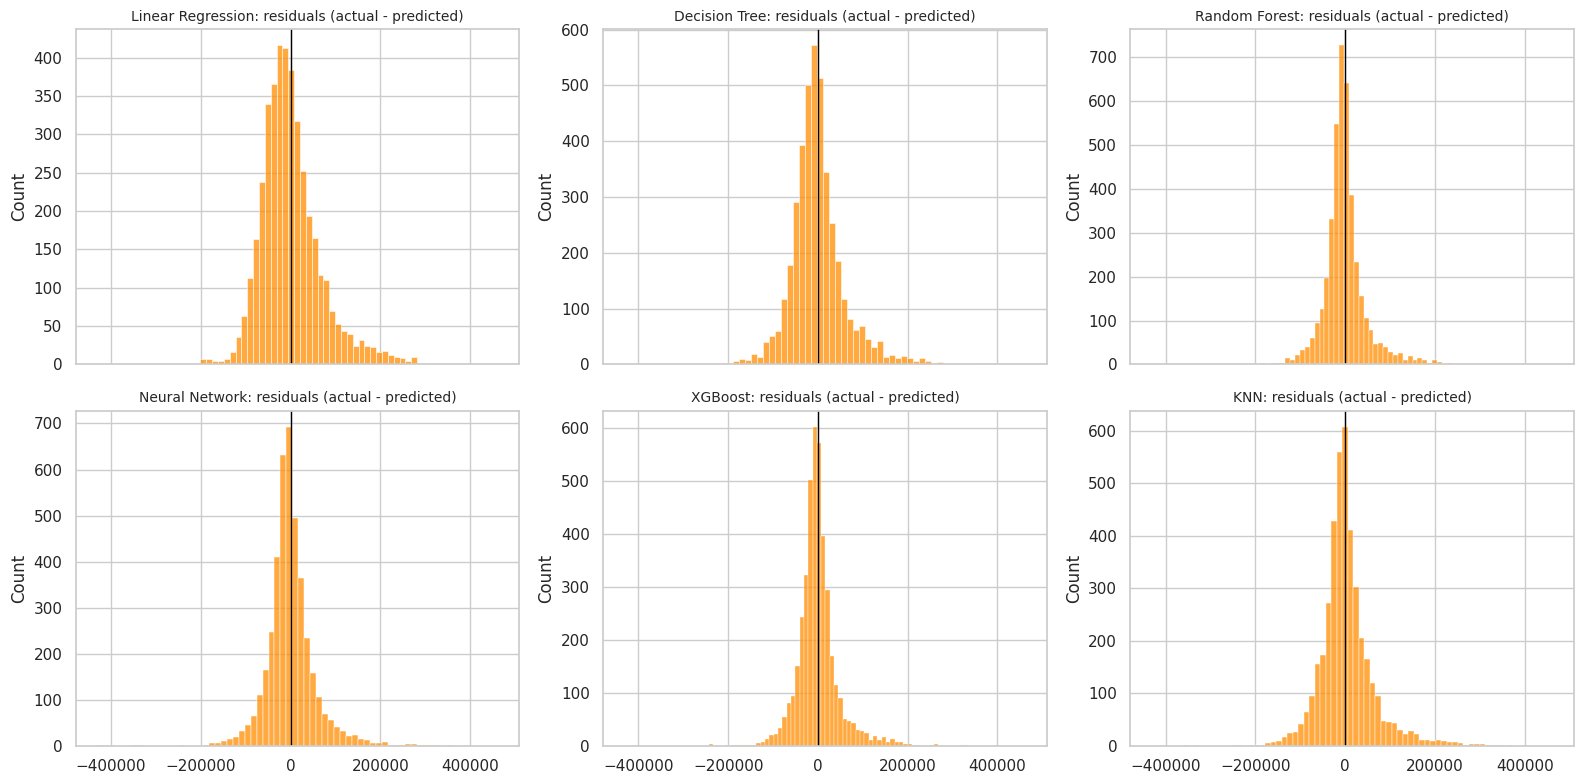

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for ax, name in zip(axes.ravel(), MODELS):
    residual = y_test.values - predictions[name]
    sns.histplot(residual, bins=60, ax=ax, color="darkorange")
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"{name}: residuals (actual - predicted)", fontsize=10)
plt.tight_layout(); plt.savefig("residuals_alt.png", dpi=200); plt.show()

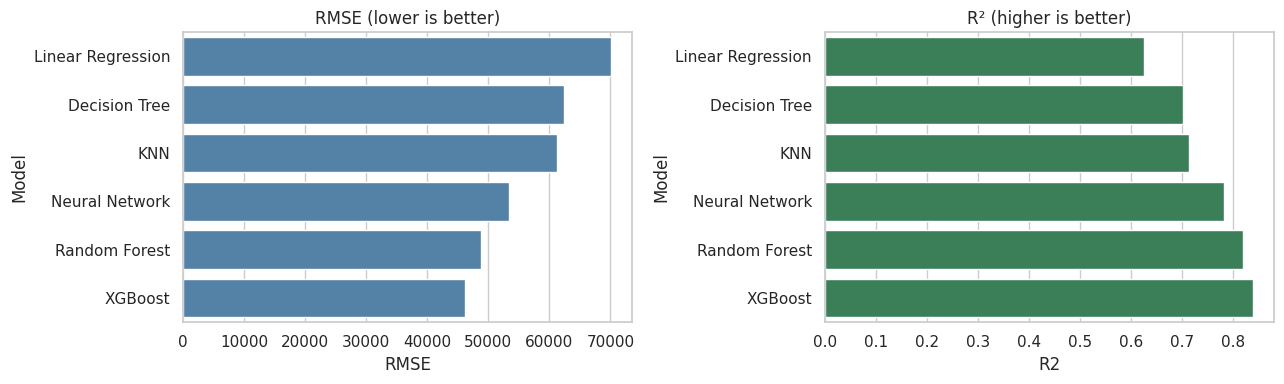

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = results.sort_values("RMSE", ascending=False)
sns.barplot(data=order, x="RMSE", y="Model", ax=ax[0], color="steelblue"); ax[0].set_title("RMSE (lower is better)")
sns.barplot(data=order.sort_values("R2"), x="R2", y="Model", ax=ax[1], color="seagreen"); ax[1].set_title("R² (higher is better)")
plt.tight_layout(); plt.show()

## 7. What drives the predictions? (tree-based models)

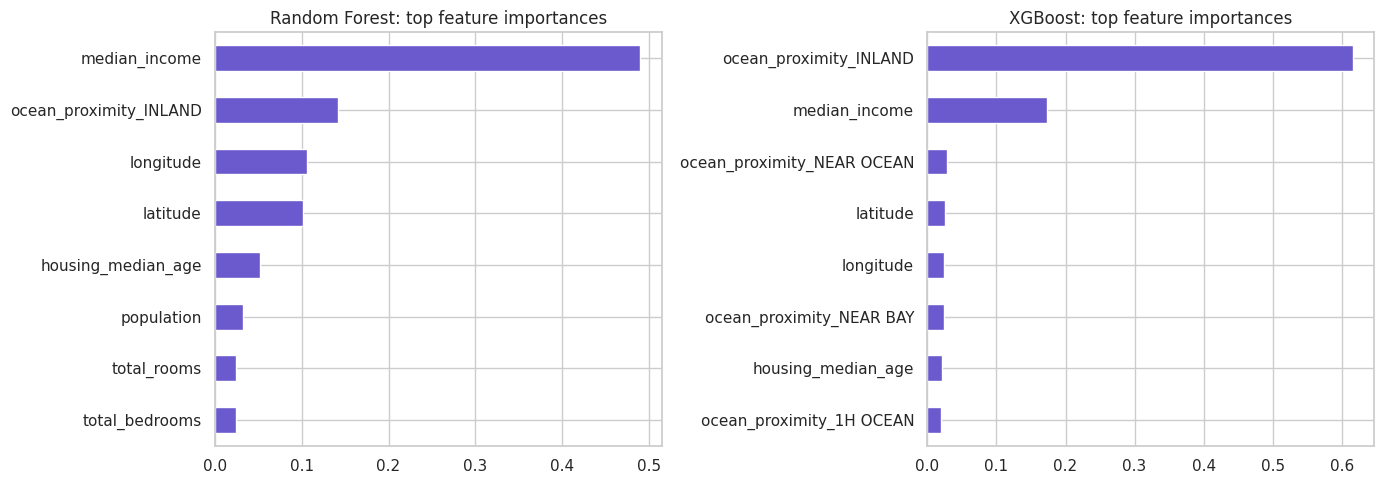

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, name in zip(ax, ["Random Forest", "XGBoost"]):
    imp = pd.Series(MODELS[name]["model"].feature_importances_, index=X_train.columns).sort_values().tail(8)
    imp.plot.barh(ax=a, color="slateblue"); a.set_title(f"{name}: top feature importances")
plt.tight_layout(); plt.show()

## 8. Conclusion

In [12]:
best, second, worst = results.iloc[0], results.iloc[1], results.iloc[-1]
print(f"Best model     : {best['Model']}  (R2 = {best['R2']:.4f}, RMSE = {best['RMSE']:,.0f}, MAE = {best['MAE']:,.0f})")
print(f"Runner-up      : {second['Model']}  (R2 = {second['R2']:.4f}, RMSE = {second['RMSE']:,.0f})")
print(f"Weakest model  : {worst['Model']}  (R2 = {worst['R2']:.4f}, RMSE = {worst['RMSE']:,.0f})")
print(f"RMSE improvement of best over runner-up: {100 * (second['RMSE'] - best['RMSE']) / second['RMSE']:.1f}%")
print(f"RMSE improvement of best over weakest  : {100 * (worst['RMSE'] - best['RMSE']) / worst['RMSE']:.1f}%")

Best model     : XGBoost  (R2 = 0.8376, RMSE = 46,129, MAE = 30,508)
Runner-up      : Random Forest  (R2 = 0.8181, RMSE = 48,823)
Weakest model  : Linear Regression  (R2 = 0.6254, RMSE = 70,059)
RMSE improvement of best over runner-up: 5.5%
RMSE improvement of best over weakest  : 34.2%
